# Dataset: Iris

## Import Libraries

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import DBSCAN

## Open Dataset

In [13]:
Iris = load_iris()

X = Iris.data
y = Iris.target

print('data:')
display(X[:5, :])
print('\n','target:')
display(y[:5])

data:


array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2]])


 target:


array([0, 0, 0, 0, 0])

## Scaling

In [16]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
display(X_scaled[:5, :])

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

## Elbow method

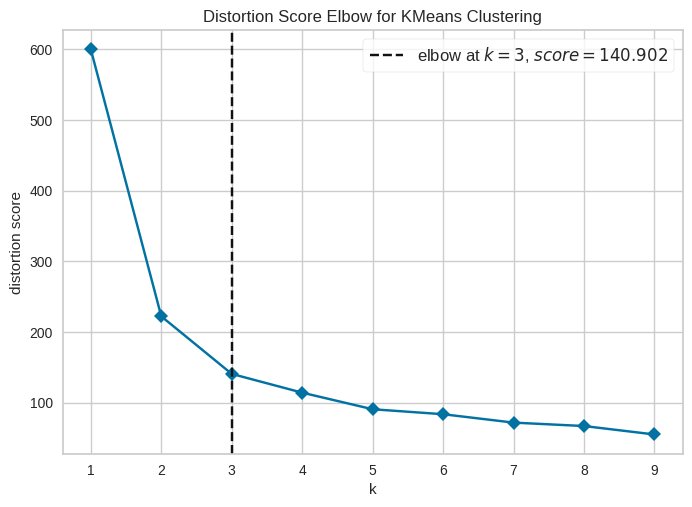

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [21]:

model = KMeans(init='k-means++', n_clusters=2, max_iter=50, random_state=10)

visualizer = KElbowVisualizer(model, k=(1,10), timings=False)

visualizer.fit(X_scaled)
visualizer.show()

## Model training

In [51]:
model_with_best_k = KMeans(n_clusters=3, init='k-means++', max_iter=300, random_state=10)

model_with_best_k.fit(X_scaled)
labels = model_with_best_k.predict(X_scaled)

In [52]:
print(f'cluster centers: {model_with_best_k.cluster_centers_}\n')
print(f'inertia: {model_with_best_k.inertia_}')

cluster centers: [[ 1.03359865  0.00613858  0.94360463  0.9725624 ]
 [-1.00206653  0.90625492 -1.30310821 -1.25634413]
 [-0.16840578 -0.9726981   0.2598706   0.17543327]]

inertia: 140.90153181202444


## Visualisation K-Means

/tmp/ipykernel_4929/2390063622.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


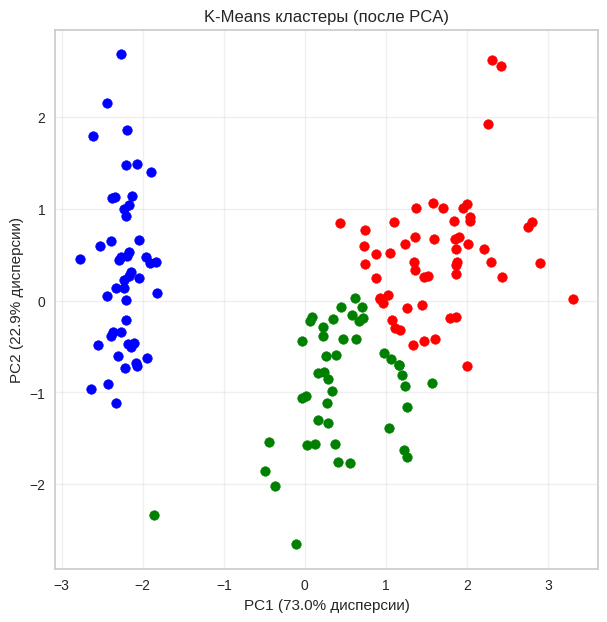

In [54]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

colors = ['red', 'blue', 'green']

plt.figure(figsize=(7,7))

for i in range(len(labels)):
  plt.scatter(X_pca[i, 0], X_pca[i, 1], color=colors[labels[i]])

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)')
plt.title('K-Means кластеры (после PCA)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [60]:
for c in np.unique(labels):
    print(f"Кластер {c} (n={(labels==c).sum()}):",
          X[labels==c].mean(axis=0).round(2))

print(pd.crosstab(labels, y).set_axis(Iris.target_names, axis=1))

Кластер 0 (n=55): [6.7  3.06 5.42 1.94]
Кластер 1 (n=49): [5.02 3.45 1.47 0.24]
Кластер 2 (n=46): [5.7  2.63 4.22 1.33]
       setosa  versicolor  virginica
row_0                               
0           0          13         42
1          49           0          0
2           1          37          8


## DBSCAN Model

In [48]:
clustering = DBSCAN(eps=0.54, min_samples=5)
clustering.fit(X_scaled)

clustering.labels_

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, -1, -1,
        0,  0,  0,  0,  0,  0,  0, -1,  0,  0,  0,  0,  0,  0,  0,  0,  1,
        1,  1,  1,  1,  1,  1, -1,  1,  1, -1,  1, -1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1, -1,  1,  1,  1,
        1,  1,  1, -1, -1, -1, -1, -1,  1,  1,  1,  1, -1,  1,  1, -1, -1,
       -1,  1,  1, -1,  1,  1, -1,  1,  1,  1, -1, -1, -1,  1,  1,  1, -1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

## Visualisation DBSCAN

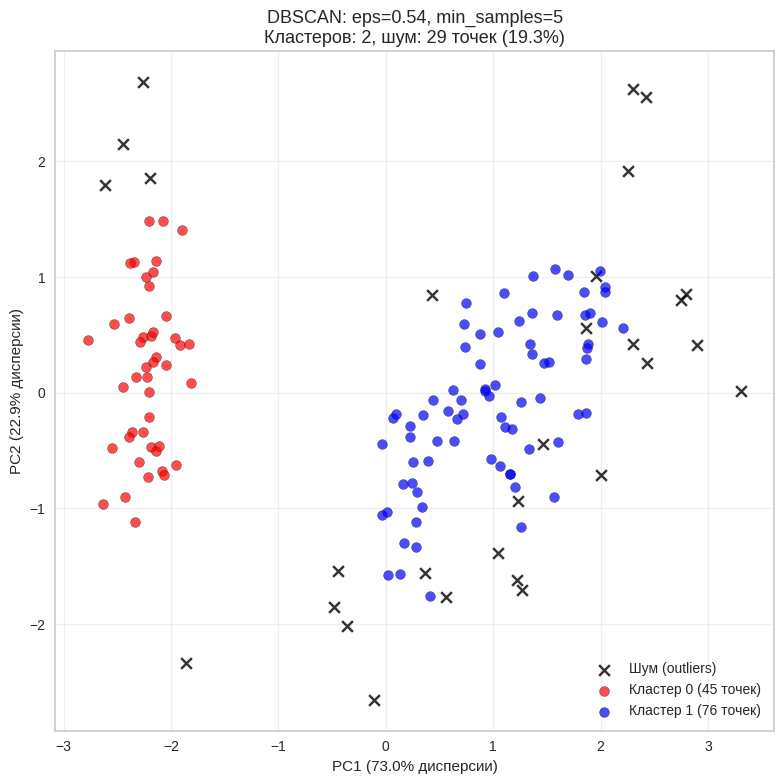

In [49]:
dbscan_labels = clustering.labels_
unique_labels = np.unique(dbscan_labels)

plt.figure(figsize=(8, 8))

# Отдельно рисуем шум (label = -1) черным
noise_mask = dbscan_labels == -1
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1],
            c='black', marker='x', s=60,
            label='Шум (outliers)', alpha=0.8)

# Кластеры — каждый своим цветом
colors = ['red', 'blue', 'green', 'purple', 'orange', 'cyan']
color_idx = 0
for label in unique_labels:
    if label == -1:
        continue
    mask = dbscan_labels == label
    n_points = mask.sum()
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[color_idx % len(colors)],
                label=f'Кластер {label} ({n_points} точек)',
                alpha=0.7, edgecolor='k', s=50)
    color_idx += 1

plt.title(f'DBSCAN: eps=0.54, min_samples=5\n'
          f'Кластеров: {len(unique_labels) - (1 if -1 in unique_labels else 0)}, '
          f'шум: {noise_mask.sum()} точек ({noise_mask.mean()*100:.1f}%)',
          fontsize=13)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% дисперсии)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% дисперсии)')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
for c in np.unique(clustering.labels_):
    if c == -1:
        continue
    print(f"Кластер {c} (n={(clustering.labels_==c).sum()}):",
          X[clustering.labels_==c].mean(axis=0).round(2))

ct = pd.crosstab(clustering.labels_, y)
ct.index = [f'Кластер {i}' if i != -1 else 'Шум (-1)' for i in ct.index]
ct.columns = Iris.target_names
print(ct)

Кластер 0 (n=45): [4.97 3.39 1.47 0.25]
Кластер 1 (n=76): [6.18 2.91 4.8  1.67]
           setosa  versicolor  virginica
Шум (-1)        5           9         15
Кластер 0      45           0          0
Кластер 1       0          41         35


## Вывод

K-Means (3 кластера)
Найденные группы:

- Кластер 0 = смесь Versicolor и Virginica (13 + 42 точек).

- Кластер 1 = Iris Setosa (49 точек).

- Кластер 2 = смесь Virginica и Versicolor и Setosa (8 + 37 + 1 точек).

DBSCAN (2 кластера + шум)
Найденные группы:

- Кластер 0 (45 точек) = Setosa.

- Кластер 1 (76 точек) = смесь Versicolor + Virginica в один большой кластер.

- Шум (29 точек) = пограничные ирисы, которые стоят далеко от плотных ядер и не попали ни в один кластер.